In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# GLOBAL STYLE SETTINGS (run once)

plt.rcParams.update({

    # --- FONT SIZES ---
    "font.size": 24,              # base font size
    "axes.titlesize": 20,         # title
    "axes.labelsize": 36,         # x/y labels
    "xtick.labelsize": 36,
    "ytick.labelsize": 36,
    "legend.fontsize": 16,

    # --- LINES ---
    "lines.linewidth": 5,
    "lines.markersize": 16,

    # --- FIGURE / AXIS ---
    "figure.figsize": (8, 6),
    "figure.dpi": 120,
    "axes.linewidth": 1.5,        # thicker axis spines

    # --- TICKS ---
    "xtick.major.size": 15,
    "xtick.major.width": 3,
    "ytick.major.size": 15,
    "ytick.major.width": 3,

    # --- LEGEND ---
    "legend.frameon": True,
    "legend.framealpha": 0.8,
    "legend.fancybox": True,

    # --- GRID (optional) ---
    #"axes.grid": True,
    #"grid.alpha": 0.3,
})


In [3]:
Frac=[]
Fit=[]
Ent=[]
Ent_base=[]

for i in range(1,101):
    df=pd.read_csv('results_dgr/simu_sub_Ntot_'+str(i)+'.csv')
    Frac.append(list(df['frac_dgr']))
    Fit.append(list(df['avg_fitness']))

AvFrac=np.mean(Frac,axis=0)
AvFit=np.mean(Fit,axis=0)

StdFrac=np.std(Frac,axis=0)
StdFit=np.std(Fit,axis=0)

FracnoDGR=[]
FitnoDGR=[]
EntnoDGR=[]
Ent_basenoDGR=[]
for i in range(1,101):
    df=pd.read_csv('results_no_dgr/simu_sub_Ntot_'+str(i)+'.csv')
    FracnoDGR.append(list(df['frac_dgr']))
    FitnoDGR.append(list(df['avg_fitness']))
    
AvFracnoDGR=np.mean(FracnoDGR,axis=0)
AvFitnoDGR=np.mean(FitnoDGR,axis=0)

StdFracnoDGR=np.std(FracnoDGR,axis=0)
StdFitnoDGR=np.std(FitnoDGR,axis=0)

FracnoDGRlowmu=[]
FitnoDGRlowmu=[]
for i in range(1,101):
    df=pd.read_csv('results_no_dgr_low_mu/simu_sub_Ntot_'+str(i)+'.csv')
    FracnoDGRlowmu.append(list(df['frac_dgr']))
    FitnoDGRlowmu.append(list(df['avg_fitness']))
    
AvFracnoDGRlowmu=np.mean(FracnoDGRlowmu,axis=0)
AvFitnoDGRlowmu=np.mean(FitnoDGRlowmu,axis=0)

StdFracnoDGRlowmu=np.std(FracnoDGRlowmu,axis=0)
StdFitnoDGRlowmu=np.std(FitnoDGRlowmu,axis=0)

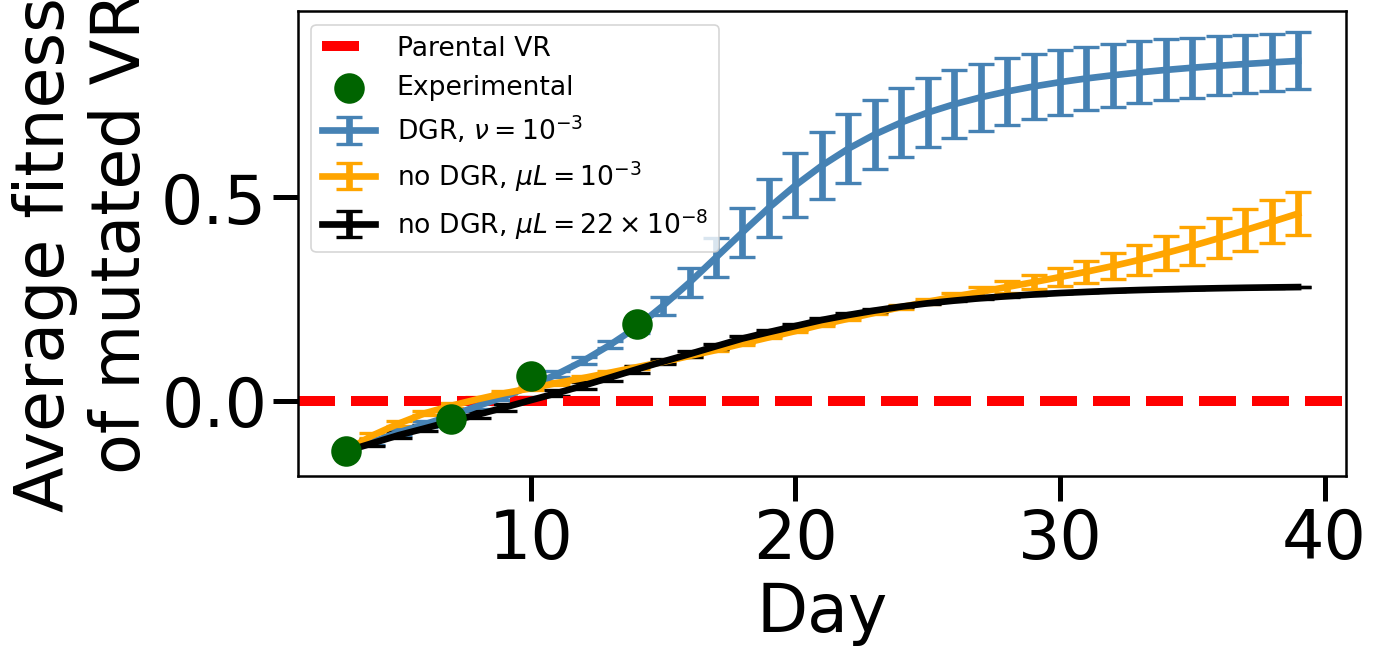

In [9]:
#--- plot with all the elements --- 

t = np.arange(3, 40)



plt.figure(figsize=(12,6))
# curva con DGR (blu)
plt.errorbar(t, AvFit[t-3], yerr=StdFit[t-3] , color='steelblue',
                 capsize=8,         # Size of the error bar caps
    markersize=2,      # Size of the markers
    elinewidth=4,      # Linewidth of the error bars (adjust this)
    capthick=2,        # Thickness of the error bar caps (optional)
    linewidth=4 ,       # Linewidth of the connecting line (for 'o-')
             label='DGR, '+r'$\nu=10^{-3}$')

plt.errorbar(t, AvFitnoDGR[t-3], yerr=StdFitnoDGR[t-3] , color='orange',
    capsize=8,         # Size of the error bar caps
    markersize=2,      # Size of the markers
    elinewidth=4,      # Linewidth of the error bars (adjust this)
    capthick=2,        # Thickness of the error bar caps (optional)
    linewidth=4 ,       # Linewidth of the connecting line (for 'o-')
             label='no DGR, '+r'$\mu L=10^{-3}$')

plt.errorbar(t, AvFitnoDGRlowmu[t-3], yerr=StdFitnoDGRlowmu[t-3] , color='black',
    capsize=8,         # Size of the error bar caps
    markersize=2,      # Size of the markers
    elinewidth=4,      # Linewidth of the error bars (adjust this)
    capthick=2,        # Thickness of the error bar caps (optional)
    linewidth=4 ,       # Linewidth of the connecting line (for 'o-')
             label='no DGR, '+r'$\mu L =22 \times 10^{-8}$')

# fitness parentale (rosso)
plt.axhline(y=0, color='red', 
            linestyle='--', label='Parental VR',linewidth=6)

exp_timepoints=[3,7,10,14]
avg_exp_fitness=[-0.12359663777021174, -0.04474662768750241, 0.059453973767175296, 0.18826436442482417] #see folder 'to _get_experimental_numbers'
# dati sperimentali (verde)
plt.scatter(exp_timepoints, avg_exp_fitness, marker='o', s = 300, 
         color='darkgreen', label='Experimental', zorder=10)
plt.xticks(fontsize=40)
plt.yticks(fontsize=40)
plt.xlabel("Day",fontsize=40)
plt.ylabel("Average fitness \n of mutated VR",fontsize=40)
#plt.xticks(exp_timepoints, labels=['day3', 'day7', 'day10', 'day14'])
#plt.title("Mean fitness of mutants over time")
plt.legend()
plt.tight_layout()
plt.savefig('Fitness.svg')
plt.show()

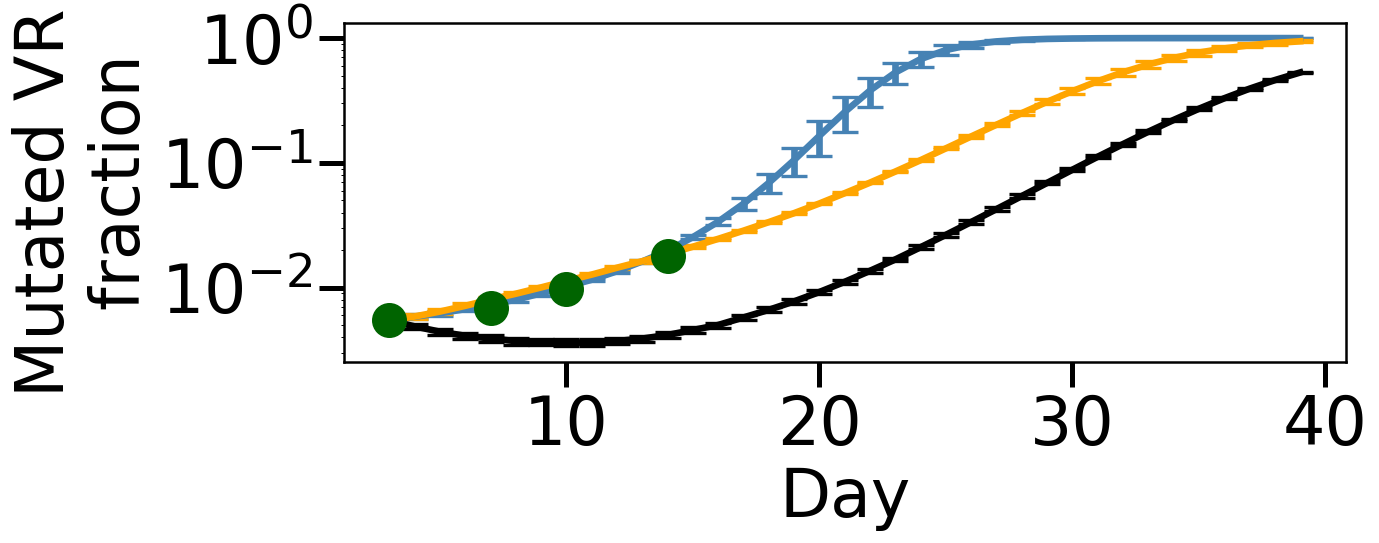

In [8]:
#--- plot with all the elements --- 

t = np.arange(3, 40)



plt.figure(figsize=(12,5))
# curva con DGR (blu)
plt.errorbar(t, AvFrac[t-3], yerr=StdFrac[t-3] , color='steelblue',
    capsize=8,         # Size of the error bar caps
    markersize=2,      # Size of the markers
    elinewidth=4,      # Linewidth of the error bars (adjust this)
    capthick=2,        # Thickness of the error bar caps (optional)
    linewidth=4 ,       # Linewidth of the connecting line (for 'o-')
             label='DGR avg ± std')

plt.errorbar(t, AvFracnoDGR[t-3], yerr=StdFracnoDGR[t-3] , color='orange',
    capsize=8,         # Size of the error bar caps
    markersize=2,      # Size of the markers
    elinewidth=4,      # Linewidth of the error bars (adjust this)
    capthick=2,        # Thickness of the error bar caps (optional)
    linewidth=4 ,       # Linewidth of the connecting line (for 'o-')
             label='no DGR avg ± std')

plt.errorbar(t, AvFracnoDGRlowmu[t-3], yerr=StdFracnoDGRlowmu[t-3] , color='black',
    capsize=8,         # Size of the error bar caps
    markersize=2,      # Size of the markers
    elinewidth=4,      # Linewidth of the error bars (adjust this)
    capthick=2,        # Thickness of the error bar caps (optional)
    linewidth=4 ,       # Linewidth of the connecting line (for 'o-')
             label='no DGR, low '+r'$\mu$'+' avg ± std')


exp_timepoints=[3,7,10,14]
avg_exp_fraction=[0.005469678953626635,
 0.0068321946342276285,
 0.00972713678693573,
 0.017767523105601396] #see folder 'to _get_experimental_numbers'
# dati sperimentali (verde)
plt.scatter(exp_timepoints, avg_exp_fraction, marker='o', s = 400, 
         color='darkgreen', label='Experimental non parental VR fraction', zorder=10)
plt.xticks(fontsize=40)
plt.yticks(fontsize=40)
plt.xlabel("Day",fontsize=40)
plt.ylabel("Mutated VR \n fraction",fontsize=40)
plt.semilogy()
#plt.xticks(exp_timepoints, labels=['day3', 'day7', 'day10', 'day14'])
#plt.legend()
plt.tight_layout()
plt.savefig('fraction.svg')
plt.show()